# 07 · Statistics, Segmentation, Prediction & Forecasting
Extends the order-to-cash analysis (notebooks 01–06) with the methods the Accenture Data & AI role asks for:
hypothesis testing, bootstrapping, regression, clustering, decision trees / gradient boosting, ARIMA, survival analysis.

**Run order:** top to bottom. Needs `olist.db` (built by notebook 03) in the same folder.
`pip install pandas numpy scipy scikit-learn matplotlib statsmodels`

In [1]:
import sqlite3, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
warnings.filterwarnings("ignore")

DB = "olist.db"
Path("figures").mkdir(exist_ok=True)
Path("tableau_exports").mkdir(exist_ok=True)
conn = sqlite3.connect(DB)
rng = np.random.default_rng(42)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 0 · One order-level table
Same definitions as the README: latest review per order, revenue = item price (freight excluded),
late = delivered on a later calendar day than the estimate, customer = `customer_unique_id`.

In [2]:
sql = """
WITH latest_review AS (
    SELECT order_id, review_score FROM (
        SELECT order_id, review_score,
               ROW_NUMBER() OVER (PARTITION BY order_id
                                  ORDER BY review_answer_timestamp DESC, review_id) AS rn
        FROM order_reviews) WHERE rn = 1),
items AS (
    SELECT oi.order_id,
           SUM(oi.price)                  AS price,
           SUM(oi.freight_value)          AS freight,
           COUNT(*)                       AS n_items,
           COUNT(DISTINCT oi.seller_id)   AS n_sellers,
           SUM(p.product_weight_g)        AS weight_g,
           MIN(oi.seller_id)              AS seller_id
    FROM order_items oi LEFT JOIN products p ON p.product_id = oi.product_id
    GROUP BY oi.order_id)
SELECT o.order_id, c.customer_unique_id, c.customer_state, s.seller_state, o.order_status,
       o.order_purchase_timestamp  AS purchase_ts,
       o.order_delivered_customer_date AS delivered_ts,
       o.order_estimated_delivery_date AS estimated_ts,
       i.price, i.freight, i.n_items, i.n_sellers, i.weight_g, r.review_score
FROM orders o
JOIN customers c          ON c.customer_id = o.customer_id
LEFT JOIN items i         ON i.order_id = o.order_id
LEFT JOIN sellers s       ON s.seller_id = i.seller_id
LEFT JOIN latest_review r ON r.order_id = o.order_id
"""
df = pd.read_sql(sql, conn, parse_dates=["purchase_ts", "delivered_ts", "estimated_ts"])

df["days_late"] = (df.delivered_ts.dt.normalize() - df.estimated_ts.dt.normalize()).dt.days
df["is_late"] = np.where(df.delivered_ts.notna(), (df.days_late > 0).astype(float), np.nan)
df["delivery_days"] = (df.delivered_ts - df.purchase_ts).dt.total_seconds() / 86400
df["promised_days"] = (df.estimated_ts - df.purchase_ts).dt.total_seconds() / 86400

delivered = df[(df.order_status == "delivered") & df.delivered_ts.notna() & df.price.notna()].copy()
delivered["is_late"] = delivered.is_late.astype(int)
print(f"delivered orders: {len(delivered):,} | late: {delivered.is_late.sum():,} ({delivered.is_late.mean():.1%})")

delivered orders: 96,470 | late: 6,534 (6.8%)


## 1 · Does late delivery really lower review scores?
README finding: late orders score ~2 stars lower. Here we test it properly.
Review scores are 1–5 (ordinal, skewed), so the main test is **Mann-Whitney U**; we also report a
**bootstrapped 95% CI** for the difference in means and then a **regression** that controls for other factors.

In [3]:
rev = delivered.dropna(subset=["review_score"]).copy()
late, ontime = rev[rev.is_late == 1].review_score.values, rev[rev.is_late == 0].review_score.values

print(f"On-time: n={len(ontime):,}, mean={ontime.mean():.2f} | Late: n={len(late):,}, mean={late.mean():.2f}")

# Mann-Whitney U + effect size (Cliff's delta: -1..1, 0 = no difference)
u, p = stats.mannwhitneyu(late, ontime, alternative="two-sided")
cliffs = 2 * u / (len(late) * len(ontime)) - 1
print(f"Mann-Whitney U p-value = {p:.2e} | Cliff's delta = {cliffs:.2f}  (negative = late orders score lower)")

# Bootstrap 95% CI for the mean difference (late - on-time)
boot = np.array([rng.choice(late, len(late)).mean() - rng.choice(ontime, len(ontime)).mean()
                 for _ in range(2000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Mean difference = {late.mean() - ontime.mean():.2f} stars, bootstrap 95% CI [{lo:.2f}, {hi:.2f}]")

On-time: n=89,443, mean=4.29 | Late: n=6,381, mean=2.27
Mann-Whitney U p-value = 0.00e+00 | Cliff's delta = -0.64  (negative = late orders score lower)
Mean difference = -2.02 stars, bootstrap 95% CI [-2.06, -1.98]


R² = 0.177
is_late (being late at all)      coef = -1.872   bootstrap 95% CI [-1.928, -1.809]
days_late (per extra day late)   coef = -0.015   bootstrap 95% CI [-0.020, -0.012]
Other controls: log price, freight ratio, promised days, items, customer state.


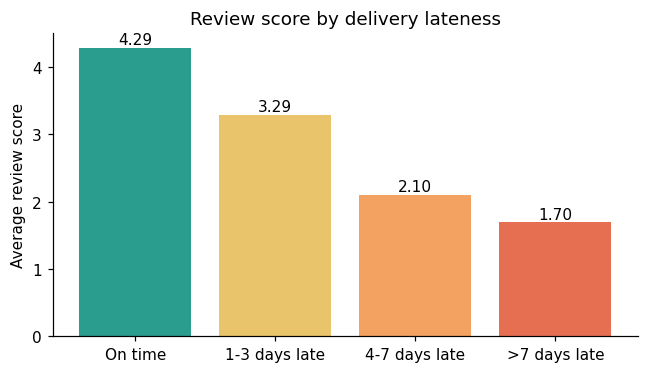

In [4]:
# Regression: review_score ~ lateness + controls (OLS via numpy; bootstrap for the CI)
rev["days_late_pos"] = rev.days_late.clip(lower=0)
rev["log_price"] = np.log1p(rev.price)
rev["freight_ratio"] = rev.freight / rev.price.replace(0, np.nan)
rev["freight_ratio"] = rev.freight_ratio.fillna(rev.freight_ratio.median()).clip(upper=2)
rev["promised_days"] = rev.promised_days

num_cols = ["is_late", "days_late_pos", "log_price", "freight_ratio", "promised_days", "n_items"]
X = pd.concat([rev[num_cols], pd.get_dummies(rev.customer_state, prefix="st", drop_first=True).astype(float)], axis=1)
X.insert(0, "const", 1.0)
y = rev.review_score.values.astype(float)
Xv = X.values.astype(float)

def ols(Xm, ym):
    beta, *_ = np.linalg.lstsq(Xm, ym, rcond=None)
    return beta

beta = ols(Xv, y)
pred = Xv @ beta
r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()

idx = [list(X.columns).index(c) for c in ["is_late", "days_late_pos"]]
boot_b = np.array([ols(Xv[i], y[i])[idx] for i in (rng.integers(0, len(y), len(y)) for _ in range(300))])
ci = np.percentile(boot_b, [2.5, 97.5], axis=0)

print(f"R² = {r2:.3f}")
for j, name in enumerate(["is_late (being late at all)", "days_late (per extra day late)"]):
    print(f"{name:32s} coef = {beta[idx[j]]:+.3f}   bootstrap 95% CI [{ci[0, j]:+.3f}, {ci[1, j]:+.3f}]")
print("Other controls: log price, freight ratio, promised days, items, customer state.")

# Bar chart: score by lateness bucket
bucket = pd.cut(rev.days_late, [-999, 0, 3, 7, 999], labels=["On time", "1-3 days late", "4-7 days late", ">7 days late"])
bt = rev.groupby(bucket, observed=True).review_score.agg(["mean", "count"]).reset_index()
bt.columns = ["bucket", "avg_score", "orders"]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(bt.bucket.astype(str), bt.avg_score, color=["#2a9d8f", "#e9c46a", "#f4a261", "#e76f51"])
ax.set_ylabel("Average review score"); ax.set_title("Review score by delivery lateness")
for i, v in enumerate(bt.avg_score): ax.text(i, v + 0.05, f"{v:.2f}", ha="center")
plt.tight_layout(); plt.savefig("figures/01_score_by_lateness.png"); plt.show()
bt.to_csv("tableau_exports/late_vs_score.csv", index=False)

**Reading it:** the Mann-Whitney test says the two score distributions differ; Cliff's delta says how big the gap is;
the bootstrap CI says how precisely we know the gap; the regression says it survives controlling for price,
freight, promised time, order size and state. Still observational: it shows association, not proof of cause.

## 2 · Customer segmentation (RFM + K-Means)
97% of customers bought once, so *frequency* barely varies. We therefore cluster on
recency, spend, average review score and a repeat flag.

94,983 customers | repeat buyers: 3.0%


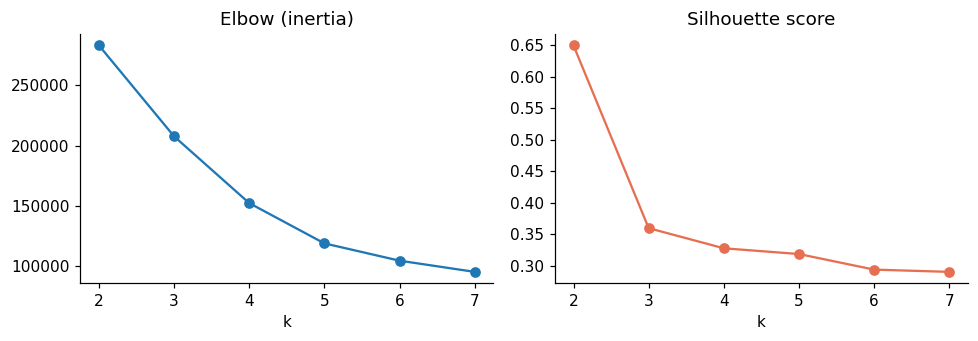

{2: np.float64(0.649), 3: np.float64(0.36), 4: np.float64(0.328), 5: np.float64(0.319), 6: np.float64(0.294), 7: np.float64(0.291)}


In [5]:
valid = df[~df.order_status.isin(["canceled", "unavailable"]) & df.price.notna()].copy()
snapshot = valid.purchase_ts.max() + pd.Timedelta(days=1)

cust = valid.groupby("customer_unique_id").agg(
    orders=("order_id", "nunique"), spend=("price", "sum"),
    last_purchase=("purchase_ts", "max"), avg_score=("review_score", "mean")).reset_index()
cust["recency_days"] = (snapshot - cust.last_purchase).dt.days
cust["is_repeat"] = (cust.orders > 1).astype(int)
cust["avg_score"] = cust.avg_score.fillna(cust.avg_score.median())
print(f"{len(cust):,} customers | repeat buyers: {cust.is_repeat.mean():.1%}")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

feat = pd.DataFrame({"recency": cust.recency_days, "log_spend": np.log1p(cust.spend),
                     "avg_score": cust.avg_score, "is_repeat": cust.is_repeat})
Z = StandardScaler().fit_transform(feat)
sample = rng.choice(len(Z), 10000, replace=False)

ks, inertias, sils = range(2, 8), [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=42).fit(Z)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Z[sample], km.labels_[sample]))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(list(ks), inertias, "o-"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), sils, "o-", color="#e76f51"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.savefig("figures/02_choose_k.png"); plt.show()
print({k: round(s, 3) for k, s in zip(ks, sils)})

In [6]:
K = 4   # chosen from the elbow + silhouette + whether the segments are explainable to a business reader
cust["segment_id"] = KMeans(K, n_init=10, random_state=42).fit_predict(Z)
profile = cust.groupby("segment_id").agg(
    customers=("customer_unique_id", "count"), avg_spend=("spend", "mean"), total_revenue=("spend", "sum"),
    avg_recency_days=("recency_days", "mean"), avg_score=("avg_score", "mean"), repeat_rate=("is_repeat", "mean")).round(2)
profile["revenue_share_%"] = (100 * profile.total_revenue / profile.total_revenue.sum()).round(1)
profile["customer_share_%"] = (100 * profile.customers / profile.customers.sum()).round(1)
profile

,customers,avg_spend,total_revenue,avg_recency_days,avg_score,repeat_rate,revenue_share_%,customer_share_%
segment_id,,,,,,,,
0,16472,160.98,2651676.80,242.39,1.63,0.0,19.7,17.3
1,43119,130.38,5621694.15,127.96,4.68,0.0,41.7,45.4
2,32505,137.53,4470561.36,398.64,4.64,0.0,33.1,34.2
3,2887,259.95,750468.43,226.57,4.16,1.0,5.6,3.0


In [7]:
# Name segments with simple rules on the profile table (so names survive a re-run); check they make sense for your run.
def name_segment(r, median_recency):
    if r.repeat_rate > 0.5: return "Repeat buyers"
    if r.avg_score < 3:     return "Unhappy one-time buyers"
    return "Recent satisfied one-timers" if r.avg_recency_days < median_recency else "Lapsed satisfied one-timers"
med_rec = profile.loc[(profile.repeat_rate <= 0.5) & (profile.avg_score >= 3), "avg_recency_days"].median()
names = {i: name_segment(r, med_rec) for i, r in profile.iterrows()}
cust["segment"] = cust.segment_id.map(names)
seg = cust.groupby("segment").agg(customers=("customer_unique_id", "count"), revenue=("spend", "sum"),
                                  avg_recency_days=("recency_days", "mean"), avg_score=("avg_score", "mean"),
                                  repeat_rate=("is_repeat", "mean")).reset_index().round(2)
seg.to_csv("tableau_exports/segments.csv", index=False)
seg

,segment,customers,revenue,avg_recency_days,avg_score,repeat_rate
0,Lapsed satisfied one-timers,32505,4470561.36,398.64,4.64,0.0
1,Recent satisfied one-timers,43119,5621694.15,127.96,4.68,0.0
2,Repeat buyers,2887,750468.43,226.57,4.16,1.0
3,Unhappy one-time buyers,16472,2651676.80,242.39,1.63,0.0


## 3 · Predicting late delivery (logistic regression, decision tree, gradient boosting)
Business use: flag orders likely to be late **at checkout** (before delivery), so the promise date can be
widened or the seller/carrier checked. So we only use information known at purchase time.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

m = delivered.copy()
m["freight_ratio"] = (m.freight / m.price.replace(0, np.nan)).fillna(0).clip(upper=2)
m["weight_g"] = m.weight_g.fillna(m.weight_g.median())
m["same_state"] = (m.customer_state == m.seller_state).astype(int)
num = ["price", "freight", "freight_ratio", "weight_g", "n_items", "n_sellers", "promised_days", "same_state"]
Xm = pd.concat([m[num],
                pd.get_dummies(m.customer_state, prefix="cust").astype(int),
                pd.get_dummies(m.seller_state.fillna("NA"), prefix="sell").astype(int)], axis=1)
ym = m.is_late.values

X_tr, X_te, y_tr, y_te = train_test_split(Xm, ym, test_size=0.25, stratify=ym, random_state=42)

models = {
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision tree (depth 4)": DecisionTreeClassifier(max_depth=4, min_samples_leaf=200, class_weight="balanced", random_state=42),
    "Gradient boosting": HistGradientBoostingClassifier(max_depth=4, learning_rate=0.08, max_iter=250, random_state=42),
}
scaler = StandardScaler().fit(X_tr[num])
def prep(Xd, name):
    if name != "Logistic regression": return Xd
    Xd = Xd.copy(); Xd[num] = scaler.transform(Xd[num]); return Xd

rows, probs = [], {}
for name, mdl in models.items():
    mdl.fit(prep(X_tr, name), y_tr)
    pr = mdl.predict_proba(prep(X_te, name))[:, 1]; probs[name] = pr
    top = pr >= np.quantile(pr, 0.90)               # flag the riskiest 10% of orders
    rows.append({"model": name, "AUC": round(roc_auc_score(y_te, pr), 3),
                 "share_of_orders_flagged": round(top.mean(), 3),
                 "late_rate_in_flagged": round(y_te[top].mean(), 3),
                 "share_of_all_late_orders_caught": round(y_te[top].sum() / y_te.sum(), 3)})
results = pd.DataFrame(rows)
print(f"Base late rate in test set: {y_te.mean():.3f}")
results

Base late rate in test set: 0.068


,model,AUC,share_of_orders_flagged,late_rate_in_flagged,share_of_all_late_orders_caught
0,Logistic regression,0.708,0.100,0.189,0.279
1,Decision tree (depth 4),0.664,0.352,0.116,0.604
2,Gradient boosting,0.719,0.100,0.195,0.288


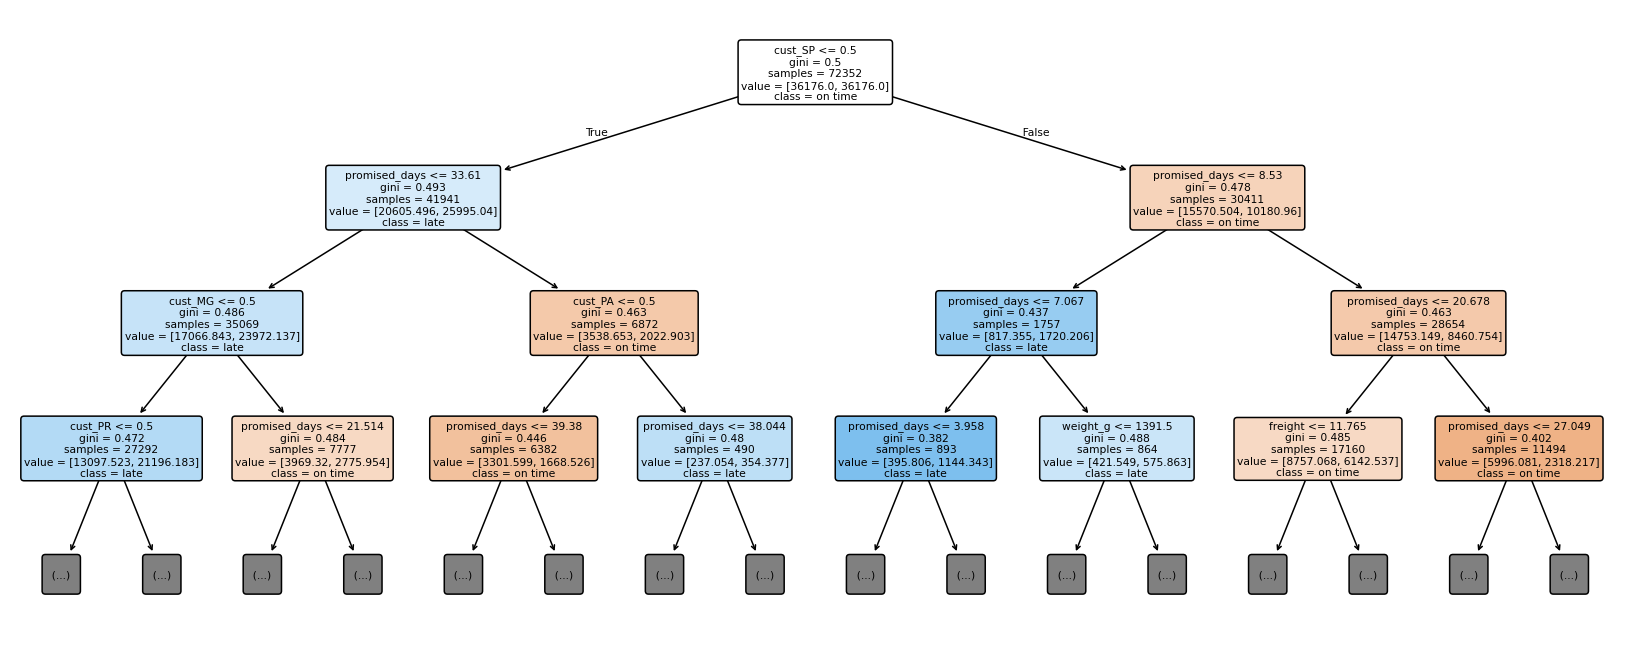

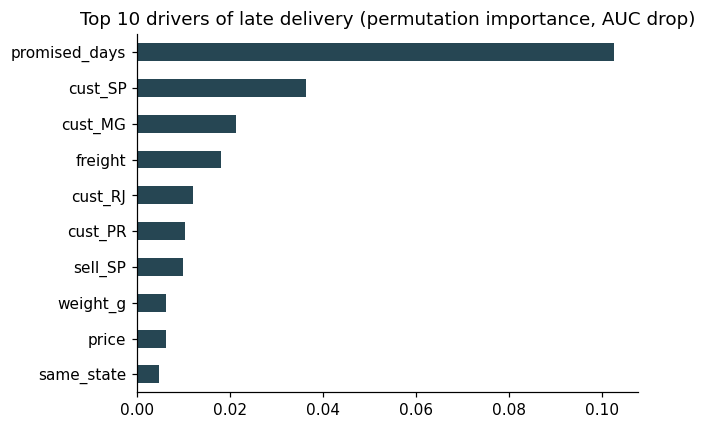

In [9]:
fig, ax = plt.subplots(figsize=(15, 6))
plot_tree(models["Decision tree (depth 4)"], feature_names=list(X_tr.columns), class_names=["on time", "late"],
          filled=True, rounded=True, fontsize=7, max_depth=3, ax=ax)
plt.tight_layout(); plt.savefig("figures/03_decision_tree.png"); plt.show()

gb = models["Gradient boosting"]
sub = X_te.sample(6000, random_state=1)
imp = permutation_importance(gb, sub, y_te[X_te.index.get_indexer(sub.index)], scoring="roc_auc", n_repeats=3, random_state=42)
imp_s = pd.Series(imp.importances_mean, index=sub.columns).sort_values(ascending=False).head(10)[::-1]
fig, ax = plt.subplots(figsize=(6, 4)); imp_s.plot.barh(ax=ax, color="#264653")
ax.set_title("Top 10 drivers of late delivery (permutation importance, AUC drop)"); plt.tight_layout()
plt.savefig("figures/03_feature_importance.png"); plt.show()

**Reading it:** AUC 0.5 = coin flip, 1.0 = perfect. The last three columns are the business view: flag the orders the model
rates riskiest (target: top 10%), what share of all late orders do we catch? A shallow decision tree gives only a few distinct
scores, so it flags more than 10% (see `share_of_orders_flagged`): compare models on the same flagged share before judging.
Caveat: random train/test split; lateness clusters in time (peak months), so real-world performance on future months may be lower.

## 4 · Forecasting monthly revenue with ARIMA
Only Jan-2017 to Aug-2018 is usable (2016 and Sep–Oct 2018 have almost no orders). That is 20 monthly points,
so we keep the model small, hold out the last 4 months, and compare against a naive baseline.

In [10]:
from statsmodels.tsa.arima.model import ARIMA

monthly = (valid.assign(month=valid.purchase_ts.dt.to_period("M").dt.to_timestamp())
           .groupby("month").price.sum())
monthly = monthly["2017-01-01":"2018-08-01"]
monthly.index = pd.DatetimeIndex(monthly.index, freq="MS")

H = 4
train, test = monthly.iloc[:-H], monthly.iloc[-H:]

best = None
for p in range(3):
    for q in range(3):
        try:
            res = ARIMA(train, order=(p, 1, q)).fit()
            if best is None or res.aic < best[0]: best = (res.aic, (p, 1, q), res)
        except Exception:
            pass
order = best[1]
fc = best[2].forecast(steps=H)

mape = lambda a, f: 100 * np.mean(np.abs((a.values - np.asarray(f)) / a.values))
naive = np.repeat(train.iloc[-1], H)
print(f"Chosen order (p,d,q) = {order} (lowest AIC on training months)")
print(f"ARIMA MAPE on held-out {H} months: {mape(test, fc):.1f}%   |   naive 'last value' MAPE: {mape(test, naive):.1f}%")

Chosen order (p,d,q) = (2, 1, 1) (lowest AIC on training months)
ARIMA MAPE on held-out 4 months: 28.2%   |   naive 'last value' MAPE: 11.3%


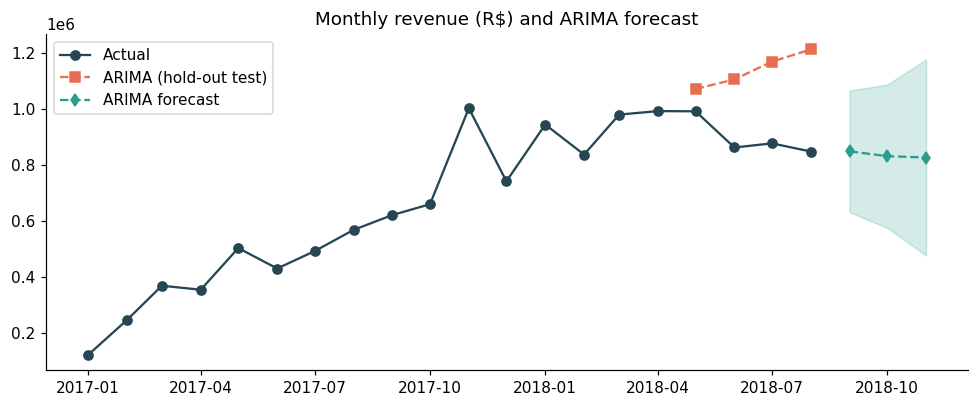

,month,revenue,lower_95,upper_95
0,2018-09-01,849418.0,631277.0,1067559.0
1,2018-10-01,832177.0,575783.0,1088571.0
2,2018-11-01,827364.0,476202.0,1178525.0


In [11]:
final = ARIMA(monthly, order=order).fit()
f3 = final.get_forecast(steps=3)
fut = pd.DataFrame({"month": f3.predicted_mean.index, "revenue": f3.predicted_mean.values,
                    "lower_95": f3.conf_int().iloc[:, 0].values, "upper_95": f3.conf_int().iloc[:, 1].values})

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(monthly.index, monthly.values, "o-", label="Actual", color="#264653")
ax.plot(test.index, np.asarray(fc), "s--", label="ARIMA (hold-out test)", color="#e76f51")
ax.plot(fut.month, fut.revenue, "d--", label="ARIMA forecast", color="#2a9d8f")
ax.fill_between(fut.month, fut.lower_95, fut.upper_95, alpha=0.2, color="#2a9d8f")
ax.set_title("Monthly revenue (R$) and ARIMA forecast"); ax.legend(); plt.tight_layout()
plt.savefig("figures/04_arima_forecast.png"); plt.show()

out = pd.concat([pd.DataFrame({"month": monthly.index, "revenue": monthly.values, "type": "Actual"}),
                 pd.DataFrame({"month": fut.month, "revenue": fut.revenue, "type": "Forecast"})])
out.to_csv("tableau_exports/monthly_revenue.csv", index=False)
fut.round(0)

**If ARIMA does not beat the naive baseline, say so.** With 20 months that is a legitimate finding, and being upfront about it
is better than hiding it.

**Caveats to state in an interview:** 20 points is very short, so seasonality (e.g. Black Friday in Nov-2017) cannot be
modelled; the forecast interval is wide for that reason. ARIMA is a baseline; the value here is a correct, honest process
(train/test split, baseline comparison, AIC selection), not a precise number.

## 5 · Survival analysis: how long until a customer buys again?
Event = second purchase on a later day. Customers who never return are **censored** (we only know they had not
returned by the end of the data). Question: do customers whose **first order arrived late** return more slowly?

93,350 customers | returned: 2.2%
Repeat purchase within 180 days:  first order on time 1.96%  vs  first order late 1.62%
Log-rank test: chi² = 6.42, p = 0.011


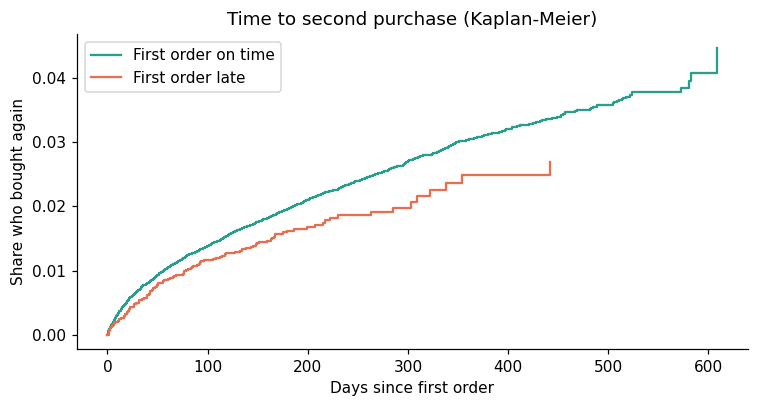

In [12]:
v = valid.copy()
v["pdate"] = v.purchase_ts.dt.normalize()
first_order = v.sort_values("purchase_ts").groupby("customer_unique_id").first()
dates = v.groupby("customer_unique_id").pdate.apply(lambda s: np.sort(s.unique()))
first_date = dates.apply(lambda a: a[0])
second_date = dates.apply(lambda a: a[1] if len(a) > 1 else pd.NaT)
end = v.pdate.max()

surv = pd.DataFrame({"first_late": first_order.is_late, "first_date": first_date, "second_date": second_date}).dropna(subset=["first_late"])
surv["event"] = surv.second_date.notna().astype(int)
surv["t"] = np.where(surv.event == 1, (surv.second_date - surv.first_date).dt.days, (end - surv.first_date).dt.days)
surv = surv[surv.t > 0]
print(f"{len(surv):,} customers | returned: {surv.event.mean():.1%}")

def kaplan_meier(t, e):
    t, e = np.asarray(t), np.asarray(e)
    times = np.sort(np.unique(t[e == 1])); S, curve = 1.0, [(0, 1.0)]
    for u_ in times:
        at_risk = (t >= u_).sum(); d = ((t == u_) & (e == 1)).sum()
        S *= 1 - d / at_risk; curve.append((u_, S))
    return pd.DataFrame(curve, columns=["day", "survival"])

def logrank(t1, e1, t0, e0):
    t = np.concatenate([t1, t0]); e = np.concatenate([e1, e0]); g = np.concatenate([np.ones(len(t1)), np.zeros(len(t0))])
    O = Ev = V = 0.0
    for u_ in np.sort(np.unique(t[e == 1])):
        r = t >= u_; n, n1 = r.sum(), (r & (g == 1)).sum(); d = ((t == u_) & (e == 1)).sum(); d1 = ((t == u_) & (e == 1) & (g == 1)).sum()
        O += d1; Ev += d * n1 / n
        if n > 1: V += d * (n1 / n) * (1 - n1 / n) * (n - d) / (n - 1)
    chi2 = (O - Ev) ** 2 / V
    return chi2, stats.chi2.sf(chi2, 1)

late_g, ok_g = surv[surv.first_late == 1], surv[surv.first_late == 0]
km_late, km_ok = kaplan_meier(late_g.t, late_g.event), kaplan_meier(ok_g.t, ok_g.event)
chi2, p_lr = logrank(late_g.t.values, late_g.event.values, ok_g.t.values, ok_g.event.values)

def repeat_by(km, day): return 1 - km[km.day <= day].survival.iloc[-1]
print(f"Repeat purchase within 180 days:  first order on time {repeat_by(km_ok, 180):.2%}  vs  first order late {repeat_by(km_late, 180):.2%}")
print(f"Log-rank test: chi² = {chi2:.2f}, p = {p_lr:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.step(km_ok.day, 1 - km_ok.survival, where="post", label="First order on time", color="#2a9d8f")
ax.step(km_late.day, 1 - km_late.survival, where="post", label="First order late", color="#e76f51")
ax.set_xlabel("Days since first order"); ax.set_ylabel("Share who bought again"); ax.legend()
ax.set_title("Time to second purchase (Kaplan-Meier)"); plt.tight_layout(); plt.savefig("figures/05_repeat_purchase_km.png"); plt.show()

curve = pd.concat([km_ok.assign(group="First order on time"), km_late.assign(group="First order late")])
curve["cum_repeat_prob"] = 1 - curve.survival
curve[["group", "day", "cum_repeat_prob"]].to_csv("tableau_exports/repeat_curve.csv", index=False)

**Reading it:** the curve shows the share of customers who have bought again by day *t*. The log-rank test asks whether the two
curves differ more than chance. Repeat buying is rare (~3%) so differences are small in absolute terms: say so plainly.

## 6 · Exports for the Tableau / Power BI dashboard

In [13]:
st = delivered.groupby("customer_state").agg(delivered_orders=("order_id", "count"), late_pct=("is_late", "mean"),
        avg_delivery_days=("delivery_days", "mean"), avg_score=("review_score", "mean")).reset_index()
st["late_pct"] = (100 * st.late_pct).round(1)
st[["avg_delivery_days", "avg_score"]] = st[["avg_delivery_days", "avg_score"]].round(2)
state_names = {"AC":"Acre","AL":"Alagoas","AP":"Amapá","AM":"Amazonas","BA":"Bahia","CE":"Ceará","DF":"Distrito Federal",
 "ES":"Espírito Santo","GO":"Goiás","MA":"Maranhão","MT":"Mato Grosso","MS":"Mato Grosso do Sul","MG":"Minas Gerais",
 "PA":"Pará","PB":"Paraíba","PR":"Paraná","PE":"Pernambuco","PI":"Piauí","RJ":"Rio de Janeiro","RN":"Rio Grande do Norte",
 "RS":"Rio Grande do Sul","RO":"Rondônia","RR":"Roraima","SC":"Santa Catarina","SP":"São Paulo","SE":"Sergipe","TO":"Tocantins"}
st.insert(1, "state_name", st.customer_state.map(state_names)); st.insert(2, "country", "Brazil")
st.to_csv("tableau_exports/state_delivery.csv", index=False)
print(sorted(Path("tableau_exports").glob("*.csv")))

[WindowsPath('tableau_exports/late_vs_score.csv'), WindowsPath('tableau_exports/monthly_revenue.csv'), WindowsPath('tableau_exports/repeat_curve.csv'), WindowsPath('tableau_exports/segments.csv'), WindowsPath('tableau_exports/state_delivery.csv')]
